# Caso Práctico: Redes Neuronales Convolucionales (CNN)

**Curso:** Introducción al Aprendizaje Profundo - Segunda entrega

**Equipo:** Juan José Herrera y Santiago Rodríguez

**Repositorio (más información):** https://github.com/JuanJoseHQ/introduccion_aprendizaje_profundo

## Conjunto de datos: Fashion-MNIST

### Descripción
Fashion-MNIST, publicado por Zalando Research en 2017, contiene 70.000 imágenes de prendas de ropa en escala de grises de 28×28 píxeles, repartidas en 10 clases. Se creó como reemplazo de MNIST: tiene el mismo formato, pero es más difícil, porque varias prendas se parecen mucho entre sí.

**Fuentes:**
- Kaggle (descarga): https://www.kaggle.com/datasets/zalando-research/fashionmnist
- OpenML, ID 40996: https://www.openml.org/d/40996

| Etiqueta | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|---|
| Clase | Camiseta/top | Pantalón | Suéter | Vestido | Abrigo | Sandalia | Camisa | Zapatilla | Bolso | Botín |

## Imports

In [21]:
%matplotlib inline
import os
import copy
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

import kagglehub

torch.manual_seed(42)
np.random.seed(42)
pd.set_option("display.max_colwidth", None)

## Funciones auxiliares

In [22]:
# División 70% / 15% / 15% estratificada por clase
def train_val_test_split(X, y, rstate=42):
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, random_state=rstate, shuffle=True, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=rstate, shuffle=True, stratify=y_temp)
    return X_train, X_val, X_test, y_train, y_val, y_test

## 1. Lectura del conjunto de datos

In [41]:
ruta = kagglehub.dataset_download("zalando-research/fashionmnist/versions/4")

df = pd.concat([pd.read_csv(os.path.join(ruta, "fashion-mnist_train.csv"), dtype="uint8"),
                pd.read_csv(os.path.join(ruta, "fashion-mnist_test.csv"), dtype="uint8")],
               ignore_index=True)
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [42]:
CLASES = ["Camiseta/top", "Pantalón", "Suéter", "Vestido", "Abrigo",
          "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]

# Cada fila de 784 píxeles se reorganiza como una imagen de 28x28
y = df["label"].to_numpy().astype(np.int64)
X = df.drop(columns="label").to_numpy().reshape(-1, 28, 28)

## 2. Visualización del conjunto de datos

In [25]:
print("Número total de imágenes:", len(X))
print("Número de clases:", len(np.unique(y)))
print("Dimensiones originales:", X.shape[1:])
print("Rango de los píxeles:", X.min(), "-", X.max())

Número total de imágenes: 70000
Número de clases: 10
Dimensiones originales: (28, 28)
Rango de los píxeles: 0 - 255


In [26]:
# 7000 imágenes por clase: el conjunto está balanceado
pd.Series(y).value_counts().sort_index().rename(index=dict(enumerate(CLASES))).to_frame("Imágenes")

,Imágenes
Camiseta/top,7000
Pantalón,7000
Suéter,7000
Vestido,7000
Abrigo,7000
Sandalia,7000
Camisa,7000
Zapatilla,7000
Bolso,7000
Botín,7000


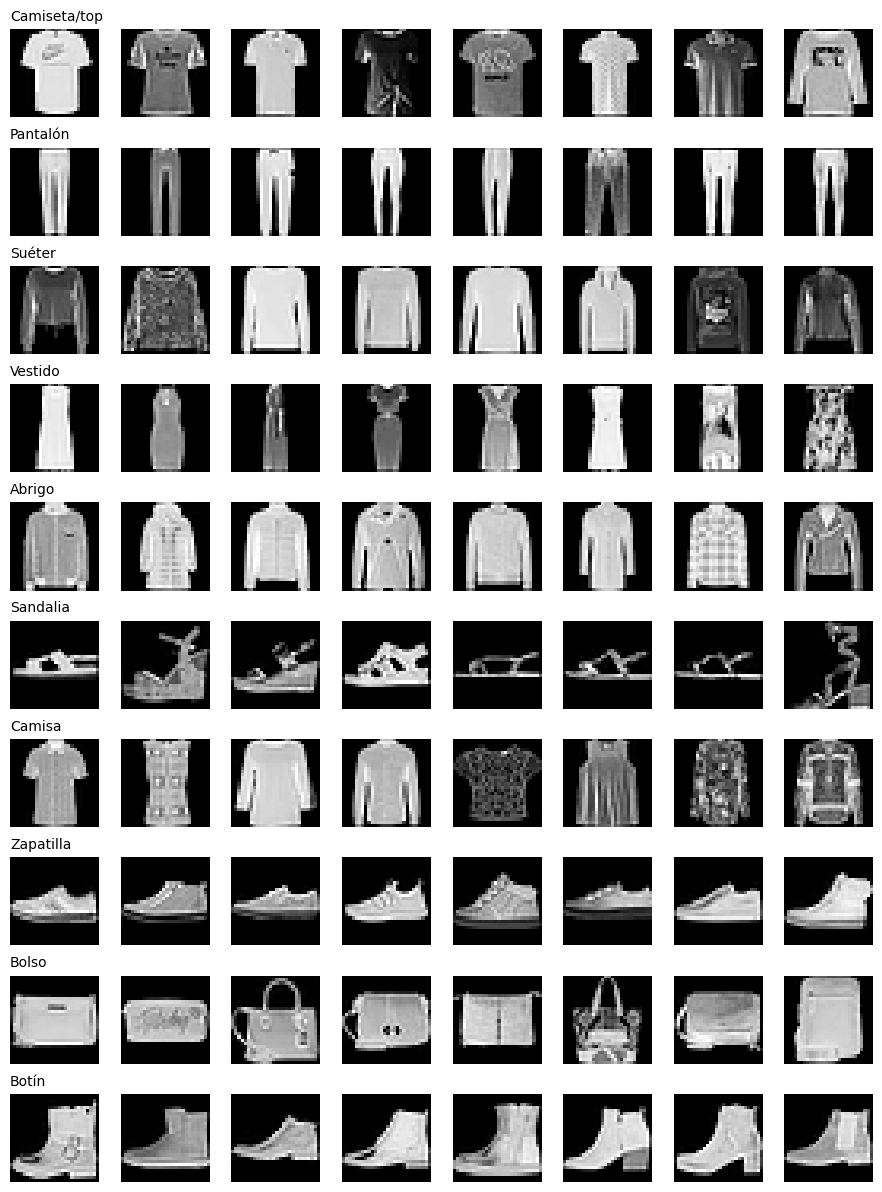

In [27]:
# Ocho ejemplos aleatorios de cada clase
rng = np.random.default_rng(42)
fig, ejes = plt.subplots(10, 8, figsize=(9, 12))
for clase in range(10):
    for j, idx in enumerate(rng.choice(np.where(y == clase)[0], 8, replace=False)):
        ejes[clase, j].imshow(X[idx], cmap="gray")
        ejes[clase, j].axis("off")
    ejes[clase, 0].set_title(CLASES[clase], loc="left", fontsize=10)
plt.tight_layout()
plt.show()

**¿Por qué este conjunto se puede abordar con una CNN?** Lo que distingue una prenda de otra son patrones espaciales muy especificos que pueden aparecer en distintas posiciones de la imagen, una red de convolución detecta esos patrones con filtros pequeños que se reutilizan en toda la imagen.
Adicionalmente las imágenes tienen un tamaño fijo para todo el conjunto y hay buena cantidad de datos para entrenar, validar y probar.

## 3. Preparación del conjunto de datos

### 3.1. División del conjunto de datos

Proporción **70 % entrenamiento / 15 % validación / 15 % prueba**, estratificada por clase para que cada subconjunto tenga las 10 clases en la misma proporción.

In [28]:
X_train, X_val, X_test, y_train, y_val, y_test = train_val_test_split(X, y)

for nombre, ys in [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]:
    print("%-13s | imágenes: %5d (%.0f%%) | por clase: %d"
          % (nombre, len(ys), 100 * len(ys) / len(y), np.bincount(ys)[0]))

Entrenamiento | imágenes: 49000 (70%) | por clase: 4900
Validación    | imágenes: 10500 (15%) | por clase: 1050
Prueba        | imágenes: 10500 (15%) | por clase: 1050


### 3.2. Transformaciones

Todas las imágenes ya miden 28×28, así que no hace falta cambiar el tamaño. Se convierten a tensores , se añade la dimensión de canal y se normalizan con la media y la desviación del conjunto de entrenamiento.

In [29]:
def a_tensor(X_np):
    # uint8 [N, 28, 28] -> float32 [N, 1, 28, 28] en el rango [0, 1]
    return torch.tensor(X_np, dtype=torch.float32).unsqueeze(1) / 255.0

X_train_t, X_val_t, X_test_t = a_tensor(X_train), a_tensor(X_val), a_tensor(X_test)

# Normalización con estadísticos solo de entrenamiento
media, desv = X_train_t.mean(), X_train_t.std()
X_train_t = (X_train_t - media) / desv
X_val_t = (X_val_t - media) / desv
X_test_t = (X_test_t - media) / desv

y_train_t = torch.tensor(y_train)
y_val_t = torch.tensor(y_val)
y_test_t = torch.tensor(y_test)

print("Media: %.4f | Desviación: %.4f" % (media, desv))

Media: 0.2857 | Desviación: 0.3525


### 3.3. DataLoaders

Lotes de 128 imágenes. Solo el conjunto de entrenamiento se baraja en cada época.

In [30]:
BATCH_SIZE = 128

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE)

x_lote, _ = next(iter(train_loader))
print("Forma de un lote [B, C, H, W]:", list(x_lote.shape))

Forma de un lote [B, C, H, W]: [128, 1, 28, 28]


**`[B, C, H, W]` = `[128, 1, 28, 28]`:** **B** es el número de imágenes del lote, **C** el número de canales (1 porque es escala de grises), y **H** y **W** el alto y el ancho en píxeles.

## 4. Red Neuronal Convolucional (CNN) con PyTorch

### 4.1. Arquitectura

- **Tres bloques `Conv2d → ReLU → MaxPool2d`** con 32, 64 y 128 filtros de 3×3, *stride* 1 y *padding* 1. La convolución mantiene el tamaño y el *pooling* 2×2 lo reduce a la mitad: 28 → 14 → 7 → 3.
- **Clasificador:** `Flatten` (128·3·3 = 1.152) → `Linear(256)` + ReLU + `Dropout(0.3)` → `Linear(10)`, una salida por clase.

In [31]:
class CNNFashion(nn.Module):
    def __init__(self, num_clases=10):
        super().__init__()
        self.capas = nn.Sequential(OrderedDict([
            ("conv1", nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)),
            ("relu1", nn.ReLU()),
            ("pool1", nn.MaxPool2d(kernel_size=2, stride=2)),
            ("conv2", nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)),
            ("relu2", nn.ReLU()),
            ("pool2", nn.MaxPool2d(kernel_size=2, stride=2)),
            ("conv3", nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)),
            ("relu3", nn.ReLU()),
            ("pool3", nn.MaxPool2d(kernel_size=2, stride=2)),
            ("flatten", nn.Flatten()),
            ("fc1", nn.Linear(128 * 3 * 3, 256)),
            ("relu4", nn.ReLU()),
            ("dropout", nn.Dropout(0.3)),
            ("fc2", nn.Linear(256, num_clases)),
        ]))

    def forward(self, x):
        return self.capas(x)


modelo = CNNFashion()
print(modelo)

CNNFashion(
  (capas): Sequential(
    (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu1): ReLU()
    (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu2): ReLU()
    (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu3): ReLU()
    (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (flatten): Flatten(start_dim=1, end_dim=-1)
    (fc1): Linear(in_features=1152, out_features=256, bias=True)
    (relu4): ReLU()
    (dropout): Dropout(p=0.3, inplace=False)
    (fc2): Linear(in_features=256, out_features=10, bias=True)
  )
)


Tabla de la arquitectura. La dimensión de salida de cada capa se obtiene haciendo pasar un lote de prueba por la red.

In [32]:
def configuracion(capa):
    if isinstance(capa, nn.Conv2d):
        return "entrada=%d, filtros=%d, kernel=%d, stride=%d, padding=%d" % (
            capa.in_channels, capa.out_channels, capa.kernel_size[0], capa.stride[0], capa.padding[0])
    if isinstance(capa, nn.MaxPool2d):
        return "kernel=%d, stride=%d" % (capa.kernel_size, capa.stride)
    if isinstance(capa, nn.Linear):
        return "entrada=%d, neuronas=%d" % (capa.in_features, capa.out_features)
    if isinstance(capa, nn.Dropout):
        return "p=%.1f" % capa.p
    return ""

filas = [("Entrada", "imagen en escala de grises", "[B, 1, 28, 28]", 0)]
x = torch.zeros(1, 1, 28, 28)
with torch.no_grad():
    for nombre, capa in modelo.capas.named_children():
        x = capa(x)
        filas.append((nombre, configuracion(capa), "[B, " + ", ".join(map(str, x.shape[1:])) + "]",
                      sum(p.numel() for p in capa.parameters())))

tabla = pd.DataFrame(filas, columns=["Capa", "Configuración", "Dimensión de salida", "Parámetros"])
print("Parámetros totales:", tabla["Parámetros"].sum())
tabla

Parámetros totales: 390410


,Capa,Configuración,Dimensión de salida,Parámetros
0,Entrada,imagen en escala de grises,"[B, 1, 28, 28]",0
1,conv1,"entrada=1, filtros=32, kernel=3, stride=1, padding=1","[B, 32, 28, 28]",320
2,relu1,,"[B, 32, 28, 28]",0
3,pool1,"kernel=2, stride=2","[B, 32, 14, 14]",0
4,conv2,"entrada=32, filtros=64, kernel=3, stride=1, padding=1","[B, 64, 14, 14]",18496
5,relu2,,"[B, 64, 14, 14]",0
6,pool2,"kernel=2, stride=2","[B, 64, 7, 7]",0
7,conv3,"entrada=64, filtros=128, kernel=3, stride=1, padding=1","[B, 128, 7, 7]",73856
8,relu3,,"[B, 128, 7, 7]",0
9,pool3,"kernel=2, stride=2","[B, 128, 3, 3]",0


### 4.2. Entrenamiento

- **Función de pérdida:** `CrossEntropyLoss` (clasificación multiclase).
- **Optimizador:** Adam, con *learning rate* 0,001.
- ***Batch size*:** 128.
- **Épocas:** 20.

En cada época se registran la pérdida y la *accuracy* de entrenamiento y validación, y se guardan los pesos de la época con menor pérdida de validación.

In [ ]:
EPOCAS = 20
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)

historial = []
mejor_val_loss = float("inf")

for epoca in range(1, EPOCAS + 1):

    # --- Entrenamiento ---
    modelo.train()
    perdida_train, aciertos_train, total_train = 0.0, 0, 0
    for x_lote, y_lote in train_loader:
        optimizador.zero_grad()               # limpiamos gradientes
        logits = modelo(x_lote)               # predicción
        perdida = criterio(logits, y_lote)    # error
        perdida.backward()                    # gradientes
        optimizador.step()                    # actualizamos pesos

        perdida_train += perdida.item() * len(x_lote)
        aciertos_train += (logits.argmax(dim=1) == y_lote).sum().item()
        total_train += len(x_lote)

    # --- Validación ---
    modelo.eval()
    perdida_val, aciertos_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for x_lote, y_lote in val_loader:
            logits = modelo(x_lote)
            perdida_val += criterio(logits, y_lote).item() * len(x_lote)
            aciertos_val += (logits.argmax(dim=1) == y_lote).sum().item()
            total_val += len(x_lote)

    train_loss, train_acc = perdida_train / total_train, aciertos_train / total_train
    val_loss, val_acc = perdida_val / total_val, aciertos_val / total_val
    historial.append((epoca, train_loss, train_acc, val_loss, val_acc))

    # Guardamos los pesos de la época con menor pérdida de validación
    if val_loss < mejor_val_loss:
        mejor_val_loss, mejor_epoca = val_loss, epoca
        mejores_pesos = copy.deepcopy(modelo.state_dict())

    print("Época %2d/%d | error: %.4f - accuracy: %.4f | val_error: %.4f - val_accuracy: %.4f"
          % (epoca, EPOCAS, train_loss, train_acc, val_loss, val_acc))

Época  1/20 | error: 0.5535 - accuracy: 0.7975 | val_error: 0.3531 - val_accuracy: 0.8708
Época  2/20 | error: 0.3330 - accuracy: 0.8800 | val_error: 0.2725 - val_accuracy: 0.9001
Época  3/20 | error: 0.2792 - accuracy: 0.8989 | val_error: 0.2749 - val_accuracy: 0.8988
Época  4/20 | error: 0.2495 - accuracy: 0.9080 | val_error: 0.2484 - val_accuracy: 0.9053
Época  5/20 | error: 0.2246 - accuracy: 0.9190 | val_error: 0.2358 - val_accuracy: 0.9134
Época  6/20 | error: 0.2028 - accuracy: 0.9248 | val_error: 0.2254 - val_accuracy: 0.9199
Época  7/20 | error: 0.1862 - accuracy: 0.9320 | val_error: 0.2214 - val_accuracy: 0.9164
Época  8/20 | error: 0.1666 - accuracy: 0.9394 | val_error: 0.2260 - val_accuracy: 0.9216
Época  9/20 | error: 0.1527 - accuracy: 0.9429 | val_error: 0.2169 - val_accuracy: 0.9261
Época 10/20 | error: 0.1384 - accuracy: 0.9484 | val_error: 0.2306 - val_accuracy: 0.9233
Época 11/20 | error: 0.1243 - accuracy: 0.9532 | val_error: 0.2385 - val_accuracy: 0.9224
Época 12/2

## 5. Análisis del entrenamiento

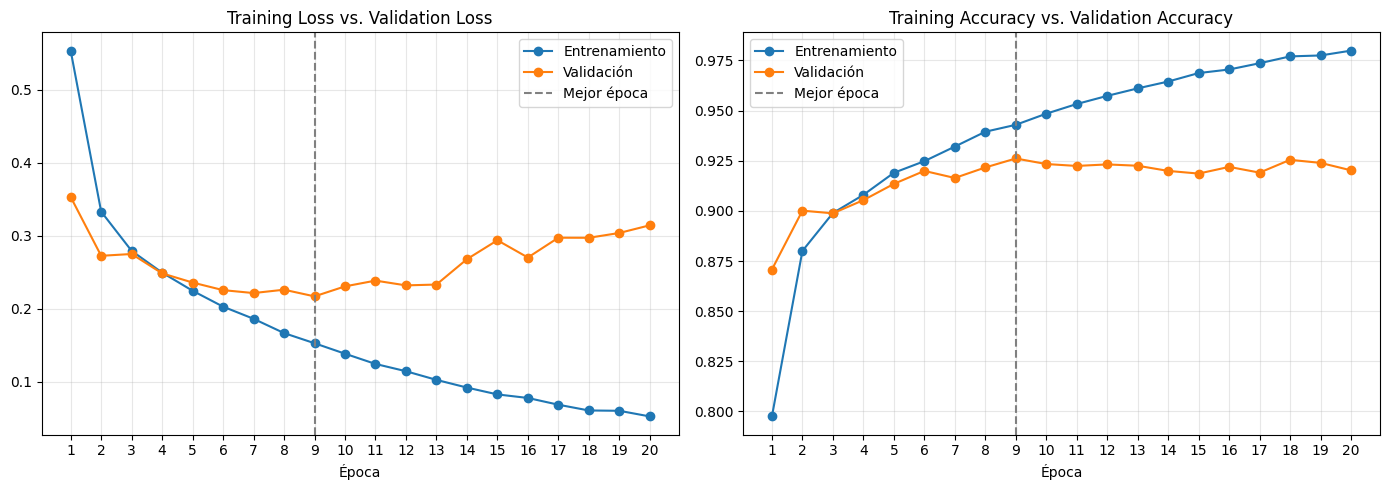

In [44]:
hist = pd.DataFrame(historial, columns=["epoca", "train_loss", "train_acc", "val_loss", "val_acc"]).set_index("epoca")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for ax, metrica, titulo in [(ax1, "loss", "Training Loss vs. Validation Loss"),
                            (ax2, "acc", "Training Accuracy vs. Validation Accuracy")]:
    ax.plot(hist.index, hist["train_" + metrica], "o-", label="Entrenamiento")
    ax.plot(hist.index, hist["val_" + metrica], "o-", label="Validación")
    ax.axvline(mejor_epoca, color="gray", linestyle="--", label="Mejor época")
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_xticks(hist.index)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**1. ¿En qué época el modelo tiene su mejor comportamiento sobre datos no vistos?** En la época 9, que es donde se tiene la menor perdida de validacion con 0,2169 y a su vez se alcanza el punto mas alto de 91,61%. 
Ya en el resto de las epocas la accuracy de validación se queda ondulando entre el 91,9 % y el 92,5 %, aunque la pérdida sisuge aumentando hasta 0,31.

**2. ¿Qué diferencias hay entre entrenamiento y validación?** En las primeras épocas, la validación va incluso por encima en la época 1: 79,8 % frente a 87,1 %, a partir de la 4 se toma una ligera venataja en donde se evidencia una tendencia positiva hasta la época 9 ambas curvas mejoran juntas, a partir de la 10 la pérdida de entrenamiento sigue bajando mientras la de validación sube, y la brecha llega a unos 6 puntos.

**3. ¿Qué modificaciones haríamos para mejorar el modelo?** Más regularización, reducir el learning rate cuando la validación se estanca, y parar el entrenamiento antes (*early stopping*).
A nivel de arquitectura, añadir algunas redes de manera estrategica para captar mejor los detalles

## 6. Evaluación sobre el conjunto de prueba

Se cargan los pesos de la mejor época y se usa el conjunto de prueba por primera vez.

In [35]:
modelo.load_state_dict(mejores_pesos)

# Predicción sobre el conjunto de prueba, lote a lote
modelo.eval()
with torch.no_grad():
    y_prob = torch.cat([torch.softmax(modelo(x_lote), dim=1) for x_lote, _ in test_loader]).numpy()

y_pred = y_prob.argmax(axis=1)
y_real = y_test

print("Accuracy : %.4f" % accuracy_score(y_real, y_pred))
print("Precisión: %.4f (macro)" % precision_score(y_real, y_pred, average="macro"))
print("Recall   : %.4f (macro)" % recall_score(y_real, y_pred, average="macro"))
print("F1       : %.4f (macro)" % f1_score(y_real, y_pred, average="macro"))
print()
print(classification_report(y_real, y_pred, target_names=CLASES, digits=4))

Accuracy : 0.9229
Precisión: 0.9231 (macro)
Recall   : 0.9229 (macro)
F1       : 0.9228 (macro)

              precision    recall  f1-score   support

Camiseta/top     0.8918    0.8867    0.8892      1050
    Pantalón     0.9942    0.9829    0.9885      1050
      Suéter     0.8985    0.8600    0.8788      1050
     Vestido     0.9179    0.9371    0.9274      1050
      Abrigo     0.8222    0.8895    0.8545      1050
    Sandalia     0.9866    0.9838    0.9852      1050
      Camisa     0.7940    0.7600    0.7766      1050
   Zapatilla     0.9607    0.9781    0.9693      1050
       Bolso     0.9885    0.9867    0.9876      1050
       Botín     0.9768    0.9638    0.9703      1050

    accuracy                         0.9229     10500
   macro avg     0.9231    0.9229    0.9228     10500
weighted avg     0.9231    0.9229    0.9228     10500



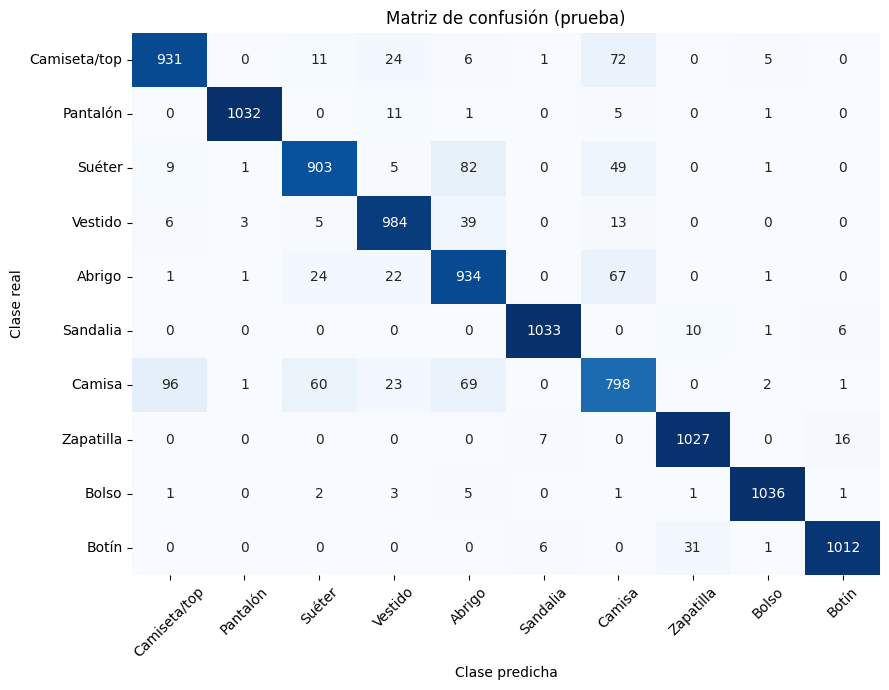

In [36]:
matriz = confusion_matrix(y_real, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASES, yticklabels=CLASES)
plt.title("Matriz de confusión (prueba)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

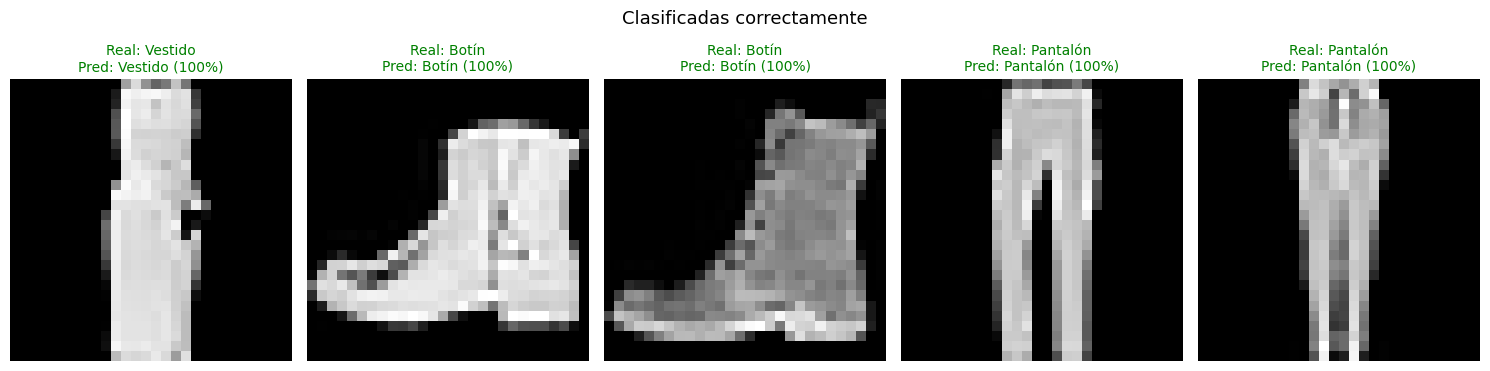

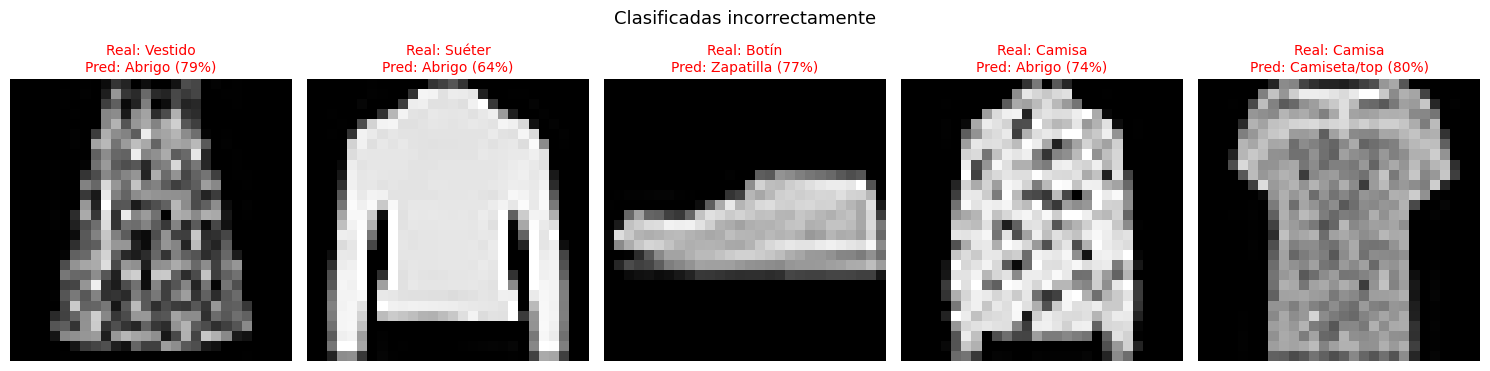

In [37]:
# Cinco imágenes bien clasificadas y cinco mal clasificadas, elegidas al azar
def mostrar_ejemplos(indices, titulo, color):
    fig, ejes = plt.subplots(1, 5, figsize=(15, 3.6))
    for ax, idx in zip(ejes, indices):
        ax.imshow(X_test[idx], cmap="gray")
        ax.set_title("Real: %s\nPred: %s (%.0f%%)" % (CLASES[y_real[idx]], CLASES[y_pred[idx]],
                                                      100 * y_prob[idx].max()), color=color, fontsize=10)
        ax.axis("off")
    plt.suptitle(titulo, fontsize=13, y=1.04)
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(42)
mostrar_ejemplos(rng.choice(np.where(y_real == y_pred)[0], 5, replace=False), "Clasificadas correctamente", "green")
mostrar_ejemplos(rng.choice(np.where(y_real != y_pred)[0], 5, replace=False), "Clasificadas incorrectamente", "red")

**Resultados.** El modelo obtiene un 2,3 % de *accuracy y un F1 macro de 0,923 en prueba, muy cerca del 92,6 % de validación.

**¿Hay clases que el modelo tienda a confundir entre sí?** Sí:
- **Prendas superiores (Camiseta/top, Suéter, Abrigo y Camisa).** Concentran la mayoría de los errore, la peor clase es Camisa (76 % de recall): 96 camisas se predicen como camiseta y 72 camisetas como camisa, y también se confunde con abrigo (69) y suéter (60).
- **Calzado.** 31 botines se predicen como zapatillas y 16 zapatillas como botines.

Entre grupos distintos casi no hay errores. Pantalón, Sandalia y Bolso superan el 98 % de *recall*. tiende a equiocarse como en una misma categoria de piesas

## 7. Preguntas de análisis
Es de mencionar que estas preguntas esta basadas en IA, nos parecio muy interesante los diversos ejercicios que implemnento la IA para responder, mas que basado en una respyesta en cada etapa hace una muestra experimental de la pregunta, con el fin de no basarse unicamente en lo teorico sino en el caso real como se ve


### Pregunta 1: ¿Qué características aprende cada capa convolucional?

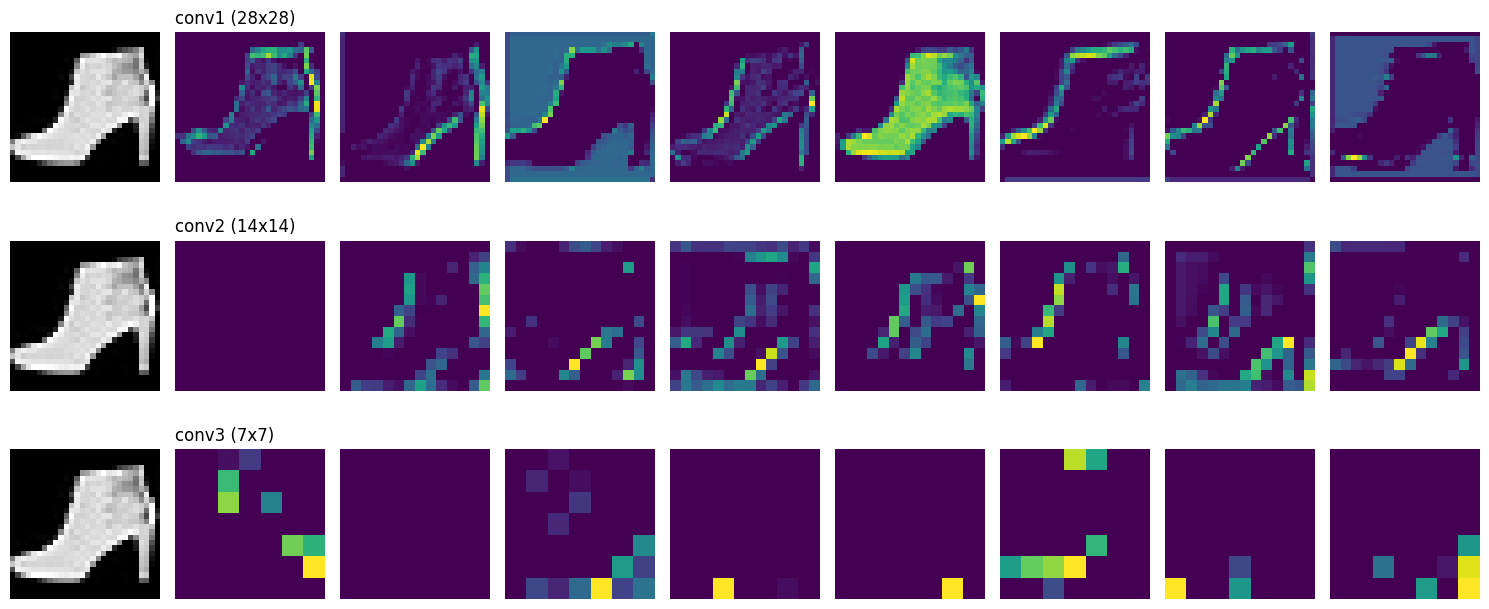

In [49]:
# Filtros 3x3 aprendidos por conv1 y mapas de activación de las tres convoluciones para una imagen
idx = 0
x = X_test_t[idx:idx + 1]
fig, ejes = plt.subplots(3, 9, figsize=(15, 6.6))
with torch.no_grad():
    fila = 0
    for nombre, capa in modelo.capas.named_children():
        x = capa(x)
        if nombre.startswith("relu") and fila < 3:
            ejes[fila, 0].imshow(X_test[idx], cmap="gray")
            for col in range(1, 9):
                ejes[fila, col].imshow(x[0, col - 1], cmap="viridis")
            ejes[fila, 1].set_title("conv%d (%dx%d)" % (fila + 1, x.shape[2], x.shape[3]), loc="left")
            fila += 1
for ax in ejes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

- **Primeras capas (`conv1`).** Cada neurona ve solo 3×3 píxeles, así que aprende **bordes, cambios de intensidad y texturas simples**, los filtros muestran zonas positivas y negativas en una dirección, como detectores de bordes, y en los mapas todavía se reconoce la prenda.
- **Capas intermedias (`conv2`).** Ven regiones de unos 8×8 píxeles y si busca un poco mas el mapeo de los bordes de la figura.
- **Capas profundas (`conv3`).** Ven unos 18×18 píxeles, casi toda la prenda, y representan patrones de alto nivel propios de cada clase. Sus mapas de 7×7 ya no se parecen a la imagen.

### Pregunta 2: ¿Cuál es el propósito del *pooling* en nuestra arquitectura?

In [ ]:
# Parámetros de fc1 con y sin las tres capas de pooling
con_pool = 128 * 3 * 3 * 256 + 256
sin_pool = 128 * 28 * 28 * 256 + 256
print("Parámetros de fc1 con pooling: %12d" % con_pool)
print("Parámetros de fc1 sin pooling: %12d  (87 veces más)" % (sin_pool, sin_pool / con_pool))

Parámetros de fc1 con pooling:       295168
Parámetros de fc1 sin pooling:     25690368  (87 veces más)


El *max pooling* 2×2 reduce el tamaño de los mapas a la mitad en cada bloque (28 → 14 → 7 → 3). Así:
- **Reduce parámetros y cómputo.** Sin *pooling*, `fc1` pasaría de 295 mil a 25,7 millones de parámetros.
- **Amplía el campo receptivo.** Gracias a él, `conv3` ve casi toda la prenda.
- **Aporta tolerancia a pequeños desplazamientos.** Al quedarse con el máximo, conserva la respuesta más fuerte de cada región y no su posición exacta.

El costo es que se pierde detalle espacial fino, justo lo que separa a una camisa de una camiseta.

### Pregunta 3: ¿Qué pasaría con los parámetros si las convoluciones se reemplazaran por capas completamente conectadas?

In [51]:
# Capa densa con las mismas entradas y salidas que cada convolución
for nombre, n_in, n_out in [("conv1", 1 * 28 * 28, 32 * 28 * 28),
                            ("conv2", 32 * 14 * 14, 64 * 14 * 14),
                            ("conv3", 64 * 7 * 7, 128 * 7 * 7)]:
    p_conv = sum(p.numel() for p in getattr(modelo.capas, nombre).parameters())
    p_densa = (n_in + 1) * n_out
    print("%s | convolucional: %7d | densa: %11d | %6.0f veces más" % (nombre, p_conv, p_densa, p_densa / p_conv))

conv1 | convolucional:     320 | densa:    19694080 |  61544 veces más
conv2 | convolucional:   18496 | densa:    78688512 |   4254 veces más
conv3 | convolucional:   73856 | densa:    19675264 |    266 veces más


El número de parámetros se dispararía: las tres convoluciones suman **92.672 parámetros**, y las capas densas equivalentes necesitarían unos **118 millones**, cerca de 1.270 veces más. Una convolución tiene pocos parámetros porque cada filtro solo mira una ventana de 3×3 (**conectividad local**) y el mismo filtro se reutiliza en toda la imagen (**pesos compartidos**). Por eso su número de parámetros no depende del tamaño de la imagen. Una capa densa conecta cada píxel con cada neurona, de modo que crece con el cuadrado del número de píxeles. El resultado sería una red mucho más lenta, que ocuparía mucha más memoria y sobreajustaría mucho más.